# **Exercícios Aula1**

1) Importe o arquivo alunos.csv e armazene seu conteúdo em um DataFrame Pandas.

2) Visualize as primeiras 7 linhas do DataFrame e as 5 últimas.

3) Confira a quantidade de linhas e colunas desse DataFrame.

4) Explore as colunas do DataFrame e analise os tipos dos dados presentes em cada coluna.

Extra: Calcule algumas estatísticas descritivas básicas dos dados do DataFrame (média, desvio padrão, etc). Dica: pesquise pelo método describe.
<br>**(fiz com describe() e manualmente)**

In [152]:
# 1) Importe o arquivo alunos.csv e armazene seu conteúdo em um DataFrame Pandas.
import pandas as pd

arquivo = 'alunos.csv'
tabela_alunos = pd.read_csv(arquivo)

# 2) Visualize as primeiras 7 linhas do DataFrame
tabela_alunos.head(7)

,Nome,Idade,Notas,Aprovado
0,Ary,20,7.5,True
1,Ana,18,NaN,False
2,Cátia,27,2.5,False
3,Denis,18,5.0,False
4,Beto,21,10.0,True
5,Bruna,23,NaN,False
6,Dara,21,7.0,True


In [153]:
# e as 5 últimas.
tabela_alunos.tail(5)

,Nome,Idade,Notas,Aprovado
13,Mirla,25,9.0,True
14,Paulo,37,NaN,False
15,Mylena,29,7.0,True
16,Lucas,33,NaN,False
17,Nadia,34,8.0,True


In [154]:
# 3) Confira a quantidade de linhas e colunas desse DataFrame.
tabela_alunos.info()

# acredito que supunham que usássemos "shape" para o item (3). Mas eu acho info() mais detalhado. Vou deixar abaixo tbm



<class 'pandas.DataFrame'>
RangeIndex: 18 entries, 0 to 17
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Nome      18 non-null     str    
 1   Idade     18 non-null     int64  
 2   Notas     12 non-null     float64
 3   Aprovado  18 non-null     bool   
dtypes: bool(1), float64(1), int64(1), str(1)
memory usage: 673.0 bytes


In [155]:
tabela_alunos.shape

(18, 4)

In [156]:
# 4) Explore as colunas do DataFrame e analise os tipos dos dados presentes em cada coluna.
# Já usei '.info()' acima, e sei que é uma coluna para cada tipo de dado.
# poderia fazer tabela_alunos[[Nome, Idade, ...]], mas são apenas 4 colunas, faço apenas tabela_alunos e aparece tudo.
 
tabela_alunos 


,Nome,Idade,Notas,Aprovado
0,Ary,20,7.5,True
1,Ana,18,NaN,False
2,Cátia,27,2.5,False
3,Denis,18,5.0,False
4,Beto,21,10.0,True
5,Bruna,23,NaN,False
6,Dara,21,7.0,True
7,Carlos,19,6.0,True
8,Alice,35,5.6,False
9,Vitor,28,NaN,False


In [157]:
# convém finalmente usar uma series, apenas pra constar:

tabela_alunos['Nome']


0           Ary
1           Ana
2         Cátia
3         Denis
4          Beto
5         Bruna
6          Dara
7        Carlos
8         Alice
9         Vitor
10       Daniel
11         Igor
12    Sthefanie
13        Mirla
14        Paulo
15       Mylena
16        Lucas
17        Nadia
Name: Nome, dtype: str

In [158]:
# Extra: Calcule algumas estatísticas descritivas básicas dos dados do DataFrame (média, desvio padrão, etc). Dica: pesquise pelo método describe.

tabela_alunos.describe()

# notar que '.describe()' dá informações apenas das colunas numéricas Idade e Notas.
# count conta o número de elementos, mean é a média, std é o desvio padrão.

,Idade,Notas
count,18.000000,12.000000
mean,25.500000,6.800000
std,6.070662,2.204953
min,18.000000,2.500000
25%,21.000000,5.450000
50%,24.500000,7.000000
75%,28.750000,8.250000
max,37.000000,10.000000


### Vou colocar aqui abaixo o cálculo 'manual' do item Extra.

In [159]:
# fazendo a média manualmente para Idade

media_manual_Idade = sum(tabela_alunos['Idade'])/len(tabela_alunos['Idade'])
media_manual_Idade

25.5

In [160]:
variancia = 0

# calculando a variância manualmente:
for idade in tabela_alunos['Idade']:
    diferenca = (idade - media_manual_Idade)**2 / (len(tabela_alunos['Idade']))   
    variancia = variancia + diferenca

# calculando o desvio padrão manualmente:
    std = variancia**(1/2)

std         # a diferença se dá porque calculei sem o '-1' na fórmula da variância. Variância populacional (que calculei) e amostral (std do describe)

5.899623340142619

In [161]:
variancia = 0

# novamente, com -1 pra provar que dá o mesmo valor do describe:
for idade in tabela_alunos['Idade']:
    diferenca = (idade - media_manual_Idade)**2 / (len(tabela_alunos['Idade']) - 1)     # aqui, apenas pra demonstrar   
    variancia = variancia + diferenca

# calculando o desvio padrão novamente:
    std = variancia**(1/2)

std

6.070662334249088

In [162]:
# para fazer os mesmos cálculos para Notas, envolve mais trabalho, porque há valores nulos. Vejamos:

# fazendo a média manualmente para Notas

media_manual_Notas = sum(tabela_alunos['Notas'])/len(tabela_alunos['Notas'])
media_manual_Notas

nan

In [163]:
# verifiquei que o nan vem do sum(tabela_alunos['Notas'])
sum(tabela_alunos['Notas'])

nan

In [164]:
# além disto, len(tabela_alunos['Notas'] me retorna um tamanho 'completo' da lista, no caso 18, mesmo com os valores nulos.
len(tabela_alunos['Notas'])

18

In [165]:
# não soube resolver o problema sem importar outra biblioteca, porque float não tem método 'notnull' e 'is not None' não resolve
# implementei a soma com math, e incluí um contador pra poder fazer a divisão posteriormente

import math

contador = 0
soma = 0
lista_notas_nao_nulos = []

for i in tabela_alunos['Notas']:
    if not math.isnan(i):
        soma += i
        contador += 1
        lista_notas_nao_nulos.append(i)   # criei esta lista para salvar apenas os valores válidos, que são 12.

soma


81.6

In [166]:
# finalmente calculando a média manualmente:

media_manual_Notas = soma / contador
media_manual_Notas

6.8

In [167]:
# calculando variâncias e desvios padrão:

variancia_populacional = 0
variancia_amostral = 0

for nota in lista_notas_nao_nulos:
    diferenca_populacional = (nota - media_manual_Notas)**2 / len(lista_notas_nao_nulos)
    diferenca_amostral = (nota - media_manual_Notas)**2 / (len(lista_notas_nao_nulos) -1 )
    variancia_populacional += diferenca_populacional
    variancia_amostral += diferenca_amostral

std_populacional_Idade = variancia_populacional**(1/2)
std_amostral_Idade = variancia_amostral**(1/2)

std_populacional_Idade
    

2.111081871142535

In [168]:
std_amostral_Idade      # mesmo que apareceu .describe(), CQD :P


2.2049531019543664

# **Exercícios Aula 2**

O time de ML chegou com algumas demandas de última hora para resolvermos nesse momento da análise exploratória. Essas demandas são:

1) Calcular a média de quartos dos imóveis;

2) Conferir quantos bairros únicos existem na nossa base de dados;

3) Analisar quais bairros possuem a média de valor de aluguel mais elevadas;

4) Criar um gráfico de barras horizontais que apresente os 5 bairros com as médias de valores de aluguel mais elevadas.

In [169]:
# As questões acima se referem ao Data Frame utilizado na aula, sobre os alugueis, então vou ter que fazer a importação/manipulação feita em aula
# pra poder começar a resolver os exercícios.

df_alugueis = pd.read_csv('aluguel.csv', sep=';')
df_alugueis

# na aula, o DF foi manipulado de forma a retirar os imoveis comerciais e posteriormente excluir todos os imóveis que não fossem apartamentos.
# como são questões simples, posso fazer para as duas hipóteses (para todos; e para os apartamentos).

,Tipo,Bairro,Quartos,Vagas,Suites,Area,Valor,Condominio,IPTU
0,Quitinete,Copacabana,1,0,0,40,1700.0,500.0,60.0
1,Casa,Jardim Botânico,2,0,1,100,7000.0,NaN,NaN
2,Conjunto Comercial/Sala,Barra da Tijuca,0,4,0,150,5200.0,4020.0,1111.0
3,Apartamento,Centro,1,0,0,15,800.0,390.0,20.0
4,Apartamento,Higienópolis,1,0,0,48,800.0,230.0,NaN
...,...,...,...,...,...,...,...,...,...
32955,Quitinete,Centro,0,0,0,27,800.0,350.0,25.0
32956,Apartamento,Jacarepaguá,3,1,2,78,1800.0,800.0,40.0
32957,Apartamento,São Francisco Xavier,2,1,0,48,1400.0,509.0,37.0
32958,Apartamento,Leblon,2,0,0,70,3000.0,760.0,NaN


In [170]:
# 1) Calcular a média de quartos dos imóveis;
df_alugueis['Quartos'].mean()

np.float64(1.7713895631067962)

In [171]:
# 2) Conferir quantos bairros únicos existem na nossa base de dados;
df_alugueis['Bairro'].unique()

# portanto, 162 bairros únicos.

<ArrowStringArray>
[         'Copacabana',     'Jardim Botânico',     'Barra da Tijuca',
              'Centro',        'Higienópolis',        'Vista Alegre',
            'Cachambi',               'Ramos',              'Grajaú',
 'Lins de Vasconcelos',
 ...
      'Cidade de Deus',    'Magalhães Bastos',         'Coelho Neto',
       'Vasco da Gama',           'Bancários',        'Rio da Prata',
       'Cidade Jardim',     'Parque Colúmbia',             'Grumari',
            'Sepetiba']
Length: 162, dtype: str

In [172]:
# 3) Analisar quais bairros possuem a média de valor de aluguel mais elevadas;
df_alugueis.groupby("Bairro")[['Valor']].mean().sort_values('Valor', ascending=False).head(10)

#botei .head(10) pra mostrar os 10 primeiros valores, já que não sabia quantos eles queriam que mostrasse

,Valor
Bairro,
Jacarepaguá,314143.489637
Irajá,154610.470588
Caju,120264.782609
Vasco da Gama,120000.000000
Cidade Nova,88166.692308
Cidade de Deus,80000.000000
Gamboa,60940.791667
Pavuna,47442.315789
Santo Cristo,45139.188406


<Axes: xlabel='bairros', ylabel='valores'>

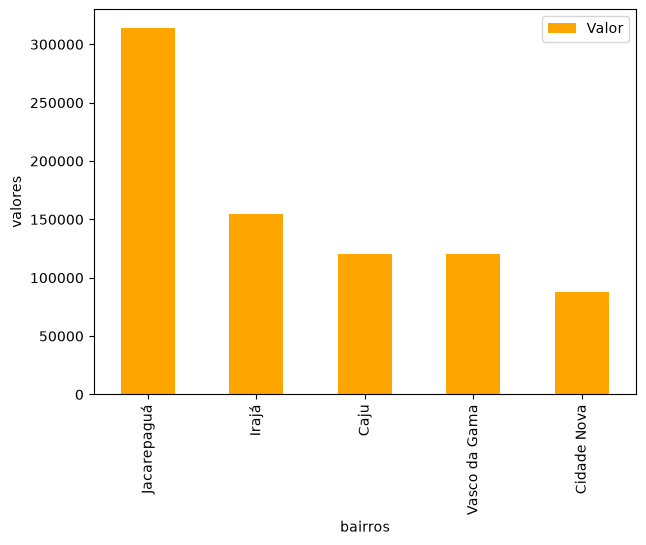

In [173]:
# 4) Criar um gráfico de barras horizontais que apresente os 5 bairros com as médias de valores de aluguel mais elevadas.
media_alugueis_por_bairro = df_alugueis.groupby("Bairro")[['Valor']].mean().sort_values('Valor', ascending=False).head(5)

# .head(5) pra mostrar apenas 5 barras.

media_alugueis_por_bairro.plot(kind='bar', figsize=(7,5), color='orange', xlabel='bairros',ylabel='valores')

### Fazendo apenas para os apartamentos, conforme a exclusão de aula:

In [174]:
df_somente_apartamentos = df_alugueis.query('Tipo == "Apartamento"')

# feito isso, basta substituir df_alugueis por df_somente_apartamentos em todos os exercícios.

In [175]:
# 1) Calcular a média de quartos dos imóveis;
df_somente_apartamentos['Quartos'].mean()

np.float64(2.481568707761622)

In [176]:
# 2) Conferir quantos bairros únicos existem na nossa base de dados;
df_somente_apartamentos['Bairro'].unique()

# portanto, 149 bairros únicos.

<ArrowStringArray>
[                 'Centro',            'Higienópolis',
            'Vista Alegre',                'Cachambi',
                  'Grajaú',     'Lins de Vasconcelos',
              'Copacabana', 'Freguesia (Jacarepaguá)',
         'Barra da Tijuca',                  'Tijuca',
 ...
                    'Tauá',                 'Ribeira',
       'Alto da Boa Vista',                  'Cacuia',
               'Bancários',              'Cavalcanti',
           'Cidade Jardim',             'Coelho Neto',
        'Magalhães Bastos',                 'Grumari']
Length: 149, dtype: str

In [177]:
# 3) Analisar quais bairros possuem a média de valor de aluguel mais elevadas;
df_somente_apartamentos.groupby("Bairro")[['Valor']].mean().sort_values('Valor', ascending=False).head(10)

,Valor
Bairro,
Joá,15500.000000
Arpoador,12429.769231
Cidade Jardim,12000.000000
Ipanema,9487.205317
Botafogo,9369.207116
Leblon,8637.761483
Lagoa,8063.804928
São Conrado,7859.871245
Jardim Oceânico,7626.086957


<Axes: xlabel='bairros', ylabel='valores'>

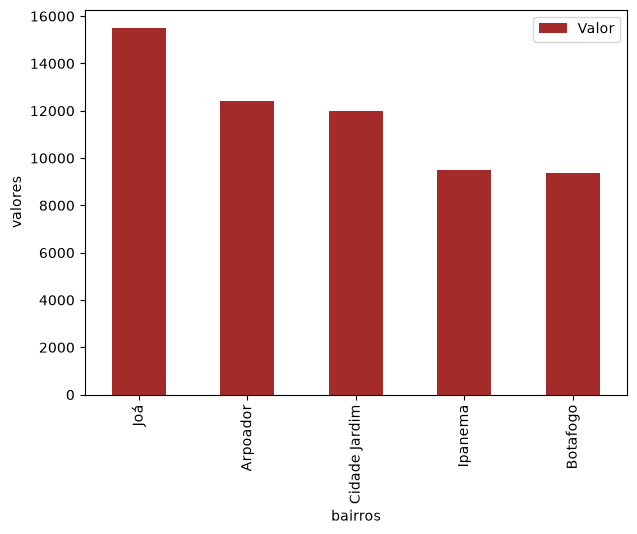

In [178]:
# 4) Criar um gráfico de barras horizontais que apresente os 5 bairros com as médias de valores de aluguel mais elevadas.
media_alugueis_bairro_apartamento = df_somente_apartamentos.groupby("Bairro")[['Valor']].mean().sort_values('Valor', ascending=False).head(5)

# .head(5) pra mostrar apenas 5 barras.

media_alugueis_bairro_apartamento.plot(kind='bar', figsize=(7,5), color='brown', xlabel='bairros',ylabel='valores')

# **Exercícios Aula 3**

1) Verifique se a base de dados possui dados nulos e, caso tenha, realize o tratamento desses dados nulos da forma que achar mais coerente com a situação.

2) Os alunos "Alice" e "Carlos", não fazem mais parte da turma. Sendo assim, remova-os da base de dados.

3) Aplique um filtro que selecione apenas os alunos que foram aprovados.

4) Salve o DataFrame que possui apenas os alunos aprovados em um arquivo csv chamado "alunos_aprovados.csv".

Extra: Ao conferir as notas dos alunos aprovados, notamos que algumas notas estavam incorretas. As alunas que tiraram nota 7.0, na verdade, tinham um ponto extra que não foi contabilizado. Sendo assim, substitua as notas 7.0 da base de dados por 8.0. Dica: pesquise pelo método replace.


In [179]:
# apenas por praticidade, vou trazer de novo o arquivo alunos.csv nesta célula

arquivo = 'alunos.csv'
tabela_alunos = pd.read_csv(arquivo)

In [180]:
# 1) Verifique se a base de dados possui dados nulos e, caso tenha, realize o tratamento desses dados nulos da forma que achar mais coerente com a situação.
tabela_alunos.isnull().sum()

# há 6 notas nulas.

Nome        0
Idade       0
Notas       6
Aprovado    0
dtype: int64

In [181]:
# tal qual no conjunto de dados de aula, é mais fácil preencher tudo com zero. Em notas de uma turma, 
# faz sentido (em outros conjuntos de dados, tem que ver caso a caso)

tabela_alunos.fillna(0, inplace=True)

,Nome,Idade,Notas,Aprovado
0,Ary,20,7.5,True
1,Ana,18,0.0,False
2,Cátia,27,2.5,False
3,Denis,18,5.0,False
4,Beto,21,10.0,True
5,Bruna,23,0.0,False
6,Dara,21,7.0,True
7,Carlos,19,6.0,True
8,Alice,35,5.6,False
9,Vitor,28,0.0,False


In [182]:
tabela_alunos.isnull().sum()

Nome        0
Idade       0
Notas       0
Aprovado    0
dtype: int64

In [183]:
# 2) Os alunos "Alice" e "Carlos", não fazem mais parte da turma. Sendo assim, remova-os da base de dados.
tabela_alunos.drop([7,8], inplace=True)     # verifiquei seus índices na tabela da célula anterior. Mas analisando posteriormente,
tabela_alunos                               # teria sido correto fazer uma query pra verificar, considerando a possiblidade de milhares de linhas

# esse é o tipo de célula que só funciona uma vez. Agora que dropou, dá erro.

,Nome,Idade,Notas,Aprovado
0,Ary,20,7.5,True
1,Ana,18,0.0,False
2,Cátia,27,2.5,False
3,Denis,18,5.0,False
4,Beto,21,10.0,True
5,Bruna,23,0.0,False
6,Dara,21,7.0,True
9,Vitor,28,0.0,False
10,Daniel,21,0.0,False
11,Igor,24,4.5,False


In [184]:
# 3) Aplique um filtro que selecione apenas os alunos que foram aprovados.
tabela_alunos.query('Aprovado == True')

,Nome,Idade,Notas,Aprovado
0,Ary,20,7.5,True
4,Beto,21,10.0,True
6,Dara,21,7.0,True
12,Sthefanie,26,9.5,True
13,Mirla,25,9.0,True
15,Mylena,29,7.0,True
17,Nadia,34,8.0,True


In [185]:
# também é possível fazer:

aprovados = tabela_alunos.Aprovado == True
alunos_aprovados = tabela_alunos[aprovados]     # criei a variável alunos_aprovados apenas pra facilitar o próximo exercício.
alunos_aprovados

,Nome,Idade,Notas,Aprovado
0,Ary,20,7.5,True
4,Beto,21,10.0,True
6,Dara,21,7.0,True
12,Sthefanie,26,9.5,True
13,Mirla,25,9.0,True
15,Mylena,29,7.0,True
17,Nadia,34,8.0,True


In [186]:
# 4) Salve o DataFrame que possui apenas os alunos aprovados em um arquivo csv chamado "alunos_aprovados.csv".

alunos_aprovados.to_csv('alunos_aprovados.csv', index=False)

In [187]:
pd.read_csv('alunos_aprovados.csv')     # apenas pra verificar que deu certo

,Nome,Idade,Notas,Aprovado
0,Ary,20,7.5,True
1,Beto,21,10.0,True
2,Dara,21,7.0,True
3,Sthefanie,26,9.5,True
4,Mirla,25,9.0,True
5,Mylena,29,7.0,True
6,Nadia,34,8.0,True


In [188]:
# Extra: Ao conferir as notas dos alunos aprovados, notamos que algumas notas estavam incorretas. As alunas que tiraram nota 7.0, 
# na verdade, tinham um ponto extra que não foi contabilizado. Sendo assim, substitua as notas 7.0 da base de dados por 8.0. 
# Dica: pesquise pelo método replace.

tabela_alunos.query('Notas == 7')       # primeiro, vendo ques dados são

,Nome,Idade,Notas,Aprovado
6,Dara,21,7.0,True
15,Mylena,29,7.0,True


In [189]:
tabela_alunos.query('Notas == 8')       # com nota 8 há apenas a Nadia

,Nome,Idade,Notas,Aprovado
17,Nadia,34,8.0,True


In [190]:
# tabela_alunos['Notas'].replace(7,8, inplace=True)
# tabela_alunos['Notas'].replace({'Notas': {7:8}}, inplace=True)       # estava me dando um erro, que eventualmente entendi que tem a ver com inplace=True

tabela_alunos['Notas'] = tabela_alunos['Notas'].replace(7,8)
tabela_alunos

,Nome,Idade,Notas,Aprovado
0,Ary,20,7.5,True
1,Ana,18,0.0,False
2,Cátia,27,2.5,False
3,Denis,18,5.0,False
4,Beto,21,10.0,True
5,Bruna,23,0.0,False
6,Dara,21,8.0,True
9,Vitor,28,0.0,False
10,Daniel,21,0.0,False
11,Igor,24,4.5,False


In [191]:
tabela_alunos.query('Notas == 7')       # agora não há mais notas 7

,Nome,Idade,Notas,Aprovado


In [192]:
tabela_alunos.query('Notas == 8')       # e, agora, Dara e Mylena tem nota 8.

,Nome,Idade,Notas,Aprovado
6,Dara,21,8.0,True
15,Mylena,29,8.0,True
17,Nadia,34,8.0,True


# **Exercícios Aula 4:**

1) Os alunos participaram de uma atividade extracurricular e ganharam pontos extras. Esses pontos extras correspondem a 40% da nota atual de cada um deles. Com base nisso, crie uma coluna chamada "Pontos_extras" que contenha os pontos extras de cada aluno, ou seja, 40% da nota atual deles.

2) Crie mais uma coluna, chamada "Notas_finais" que possua as notas de cada aluno somada com os pontos extras.

3) Como houve uma pontuação extra, alguns alunos que não tinham sido aprovados antes podem ter sido aprovados agora. Com base nisso, crie uma coluna chamada "Aprovado_final" com os seguintes valores:

    ```
    True: caso o aluno esteja aprovado (nota final deve ser maior ou igual a 6);
    False: caso o aluno esteja reprovado (nota final deve ser menor que 6).
    ```

4) Faça uma seleção e verifique quais alunos não tinham sido aprovados anteriormente, mas foram aprovados após a soma dos pontos extras.

In [193]:
# 1) Os alunos participaram de uma atividade extracurricular e ganharam pontos extras. Esses pontos extras correspondem a 40% 
# da nota atual de cada um deles. Com base nisso, crie uma coluna chamada "Pontos_extras" que contenha os pontos extras de cada aluno, 
# ou seja, 40% da nota atual deles.

tabela_alunos['Pontos_extras'] = tabela_alunos['Notas'] * 0.4
tabela_alunos

,Nome,Idade,Notas,Aprovado,Pontos_extras
0,Ary,20,7.5,True,3.0
1,Ana,18,0.0,False,0.0
2,Cátia,27,2.5,False,1.0
3,Denis,18,5.0,False,2.0
4,Beto,21,10.0,True,4.0
5,Bruna,23,0.0,False,0.0
6,Dara,21,8.0,True,3.2
9,Vitor,28,0.0,False,0.0
10,Daniel,21,0.0,False,0.0
11,Igor,24,4.5,False,1.8


In [198]:
# 2) Crie mais uma coluna, chamada "Notas_finais" que possua as notas de cada aluno somada com os pontos extras.
tabela_alunos['Notas_finais'] = tabela_alunos['Notas'] + tabela_alunos['Pontos_extras']

for i in tabela_alunos['Notas_finais']:
    if i > 10:
        tabela_alunos['Notas_finais'] = tabela_alunos['Notas_finais'].replace(i,10)

        #não pediram, mas me deu nos nervos ver notas maiores que 10 na coluna :P

tabela_alunos    

,Nome,Idade,Notas,Aprovado,Pontos_extras,Notas_finais
0,Ary,20,7.5,True,3.0,10.0
1,Ana,18,0.0,False,0.0,0.0
2,Cátia,27,2.5,False,1.0,3.5
3,Denis,18,5.0,False,2.0,7.0
4,Beto,21,10.0,True,4.0,10.0
5,Bruna,23,0.0,False,0.0,0.0
6,Dara,21,8.0,True,3.2,10.0
9,Vitor,28,0.0,False,0.0,0.0
10,Daniel,21,0.0,False,0.0,0.0
11,Igor,24,4.5,False,1.8,6.3


In [ ]:
# 3) Como houve uma pontuação extra, alguns alunos que não tinham sido aprovados antes podem ter sido aprovados agora. 
# Com base nisso, crie uma coluna chamada "Aprovado_final" com os seguintes valores:

#     ```
#     True: caso o aluno esteja aprovado (nota final deve ser maior ou igual a 6);
#     False: caso o aluno esteja reprovado (nota final deve ser menor que 6).
#     ```
# -------------------------------------------

# Percebi que este exercício era mais capcioso do que parecia inicialmente.
# Tentei o código abaixo, mas ele 'esbarra' na questão de dar um valor True ou False pra uma series inteira.
# tabela_alunos['Aprovado_final'] = True if (tabela_alunos['Notas_finais'] >= 6) else False

# depois de algumas tentativas, consegui de um jeito muito mais simples:

tabela_alunos['Aprovado_final'] = tabela_alunos['Notas_finais'] >= 6

tabela_alunos

,Nome,Idade,Notas,Aprovado,Pontos_extras,Notas_finais,Aprovado_final
0,Ary,20,7.5,True,3.0,10.0,True
1,Ana,18,0.0,False,0.0,0.0,False
2,Cátia,27,2.5,False,1.0,3.5,False
3,Denis,18,5.0,False,2.0,7.0,True
4,Beto,21,10.0,True,4.0,10.0,True
5,Bruna,23,0.0,False,0.0,0.0,False
6,Dara,21,8.0,True,3.2,10.0,True
9,Vitor,28,0.0,False,0.0,0.0,False
10,Daniel,21,0.0,False,0.0,0.0,False
11,Igor,24,4.5,False,1.8,6.3,True


In [ ]:
# 4) Faça uma seleção e verifique quais alunos não tinham sido aprovados anteriormente, mas foram aprovados após a soma dos pontos extras.
tabela_alunos.query('Aprovado == False & Aprovado_final == True')


,Nome,Idade,Notas,Aprovado,Pontos_extras,Notas_finais,Aprovado_final
3,Denis,18,5.0,False,2.0,7.0,True
11,Igor,24,4.5,False,1.8,6.3,True


In [ ]:
# ou alternativamente

reprovados_inicialmente = tabela_alunos['Aprovado'] == False
tabela_alunos[reprovados_inicialmente]

# todos os reprovados inicialmente



,Nome,Idade,Notas,Aprovado,Pontos_extras,Notas_finais,Aprovado_final
1,Ana,18,0.0,False,0.0,0.0,False
2,Cátia,27,2.5,False,1.0,3.5,False
3,Denis,18,5.0,False,2.0,7.0,True
5,Bruna,23,0.0,False,0.0,0.0,False
9,Vitor,28,0.0,False,0.0,0.0,False
10,Daniel,21,0.0,False,0.0,0.0,False
11,Igor,24,4.5,False,1.8,6.3,True
14,Paulo,37,0.0,False,0.0,0.0,False
16,Lucas,33,0.0,False,0.0,0.0,False


In [ ]:
aprovados_finalmente = tabela_alunos['Aprovado_final'] == True
tabela_alunos[aprovados_finalmente]

# todos os aprovados finalmente.
# nesta já dá pra ver só os dois False ali, sugerindo que são esses os que vão aparecer.

,Nome,Idade,Notas,Aprovado,Pontos_extras,Notas_finais,Aprovado_final
0,Ary,20,7.5,True,3.0,10.0,True
3,Denis,18,5.0,False,2.0,7.0,True
4,Beto,21,10.0,True,4.0,10.0,True
6,Dara,21,8.0,True,3.2,10.0,True
11,Igor,24,4.5,False,1.8,6.3,True
12,Sthefanie,26,9.5,True,3.8,10.0,True
13,Mirla,25,9.0,True,3.6,10.0,True
15,Mylena,29,8.0,True,3.2,10.0,True
17,Nadia,34,8.0,True,3.2,10.0,True


In [209]:
# agora, é juntar os false com os True num AND

tabela_alunos[reprovados_inicialmente & aprovados_finalmente]

,Nome,Idade,Notas,Aprovado,Pontos_extras,Notas_finais,Aprovado_final
3,Denis,18,5.0,False,2.0,7.0,True
11,Igor,24,4.5,False,1.8,6.3,True
